In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("C:\Auspify Technologies ML intern\Data\Dataset.csv")
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [44]:
print("Shape", df.shape)
print("-*" * 50)
print("Columns:", df.columns)
print("-*" * 50)
df.info()
print("-*" * 50)
print("Duplicates :", df.duplicated().sum())

Shape (8790, 10)
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
Columns: Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in'],
      dtype='object')
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: 

### Feature Selection 

In [ ]:
dataset = df[['type','country', 
             'release_year', 'rating',
             'listed_in'
]]
dataset.head(3)

,type,country,release_year,rating,listed_in
0,Movie,United States,2020,PG-13,Documentaries
1,TV Show,France,2021,TV-MA,"Crime TV Shows, International TV Shows, TV Act..."
2,TV Show,United States,2021,TV-MA,"TV Dramas, TV Horror, TV Mysteries"


###  Prepare numerical and categorical features

In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# preprocessing the data.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['release_year']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), 
         ['type', 'country', 'rating'])
    ]
)

X_basic = preprocessor.fit_transform(dataset[['type','country', 'release_year', 'rating']])

In [47]:
from sklearn.preprocessing import MultiLabelBinarizer

# We first need to split the string
dataset['genres'] = dataset['listed_in'].fillna('').apply(
    lambda x: [genre.strip() for genre in x.split(',')]
)

mlb = MultiLabelBinarizer()

genre_matrix = mlb.fit_transform(dataset['genres'])

# At the end combining the data
from scipy.sparse import hstack

X_final = hstack([
    X_basic,
    genre_matrix
])

### Silhoutte and Elbow Method

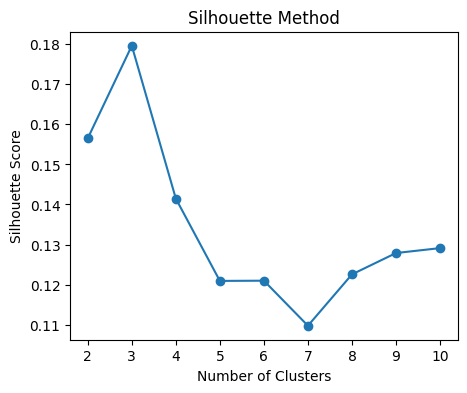

In [48]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

ss = []

for i in range(2,11):
    km = KMeans(n_clusters=i, random_state=42)
    km.fit(X_final)
    ss.append(silhouette_score(X_final, km.labels_))  
    

# Visualizing with plot   
plt.figure(figsize=(5,4))
plt.plot(range(2,11,1), ss, marker='o')  

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method")

plt.show()

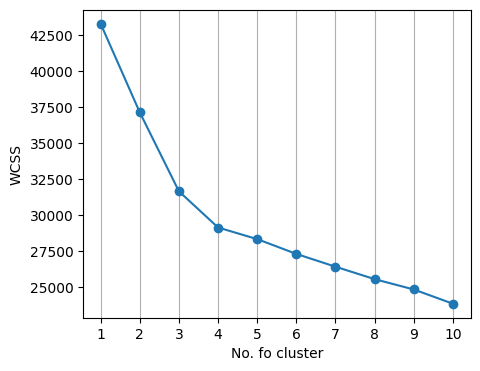

In [49]:

wcss = []

for i in range(1, 11):
    km = KMeans(n_clusters = i, random_state=42)
    km.fit(X_final)
    wcss.append(km.inertia_)
 
    
plt.figure(figsize=(5,4))
plt.plot([i for i in range(1,11)],wcss, marker='o')
plt.xlabel('No. fo cluster')
plt.ylabel('WCSS')
plt.xticks([i for i in range(1,11)])
plt.grid(axis ='x')

### Choosing the Number of Clusters

To determine the optimal number of clusters, I used both the **Silhouette Score** and the **Elbow Method**. The Silhouette Score showed the best performance at **3 clusters**, while the Elbow Method also showed a clear bend (elbow) around **3**. Since both methods provided consistent evidence, I selected **3 as the optimal number of clusters** instead of choosing a larger or smaller value.


### Applying K-means Algorithm

In [50]:
kmeans = KMeans(
    n_clusters= 3,
    random_state= 42,
    n_init= 10
)

cluster = kmeans.fit_predict(X_final)

# Adding cluster into the dataset
dataset['cluster'] = cluster

dataset.head(3)

,type,country,release_year,rating,listed_in,genres,cluster
0,Movie,United States,2020,PG-13,Documentaries,[Documentaries],0
1,TV Show,France,2021,TV-MA,"Crime TV Shows, International TV Shows, TV Act...","[Crime TV Shows, International TV Shows, TV Ac...",1
2,TV Show,United States,2021,TV-MA,"TV Dramas, TV Horror, TV Mysteries","[TV Dramas, TV Horror, TV Mysteries]",1


### Visualizing clusters

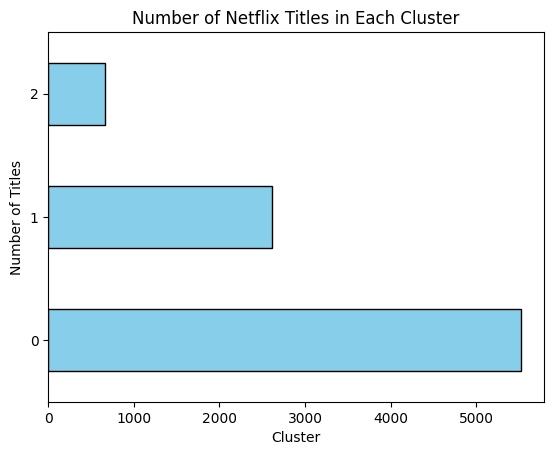

In [51]:
dataset['cluster'].value_counts().sort_index().plot(kind='barh', color='skyblue',edgecolor='black')

plt.xlabel('Cluster')
plt.ylabel('Number of Titles')
plt.title('Number of Netflix Titles in Each Cluster')
plt.show()

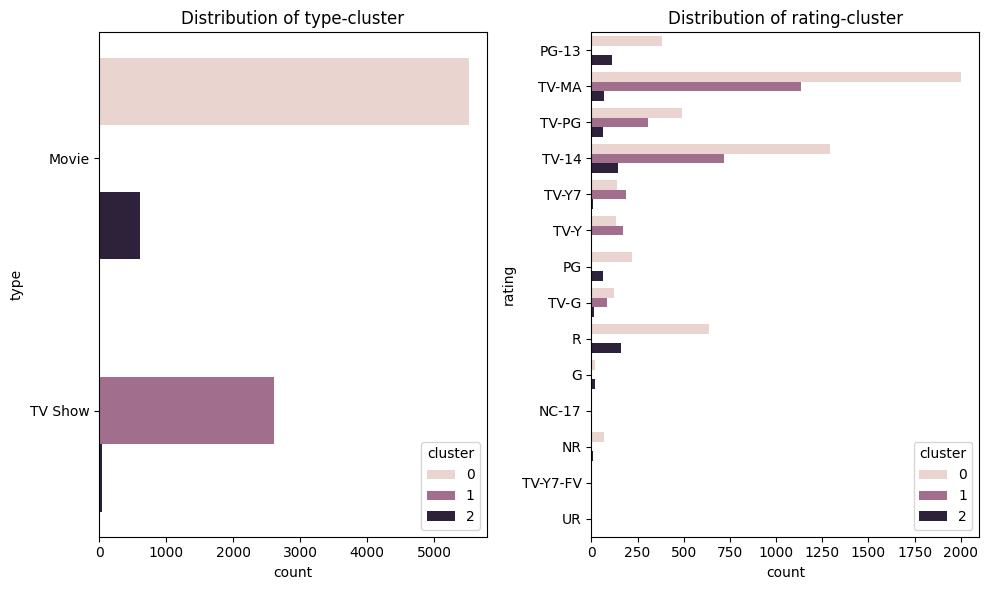

In [52]:
cols = ['type', 'rating']

plt.figure(figsize=(10,6))

for i, col in enumerate(cols):
    plt.subplot(1,2, 1+i)
    sns.countplot(y=dataset[col], hue=dataset['cluster'])
    plt.title(f"Distribution of {col}-cluster")
    
plt.tight_layout()
plt.show()

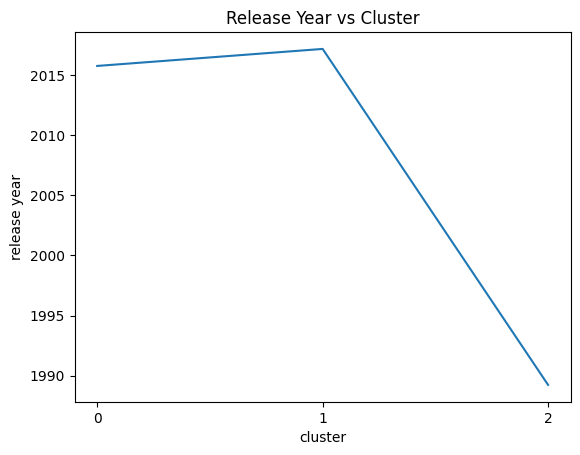

In [53]:
dataset.groupby('cluster')['release_year'].mean().plot()

plt.title('Release Year vs Cluster')
plt.xlabel('cluster')
plt.ylabel('release year')
plt.xticks(range(0,3))
plt.show()

In [54]:
genre_df = dataset.assign(
    listed_in=dataset['listed_in'].str.split(', ')
).explode('listed_in')

genre_counts = (
    genre_df.groupby('cluster')['listed_in']
    .value_counts()
    .groupby(level=0)
    .head(10)
)

print(genre_counts)

cluster  listed_in                
0        International Movies         2561
         Dramas                       2167
         Comedies                     1459
         Documentaries                 839
         Independent Movies            713
         Action & Adventure            675
         Children & Family Movies      586
         Romantic Movies               552
         Thrillers                     540
         Music & Musicals              339
1        International TV Shows       1345
         TV Dramas                     758
         TV Comedies                   559
         Crime TV Shows                467
         Kids' TV                      430
         Docuseries                    390
         Romantic TV Shows             370
         Reality TV                    253
         British TV Shows              248
         Spanish-Language TV Shows     172
2        Dramas                        259
         Comedies                      215
         Internatio

###  Interpret cluster characteristics

In [55]:
dataset['cluster_category'] = dataset['cluster'].map({
    0: 'Modern Movie-Focused Content',
    1: 'Modern TV-Focused Content',
    2: 'Older / Classic Content'
})

dataset['title'] = df['title']
dataset.head()

,type,country,release_year,rating,listed_in,genres,cluster,cluster_category,title
0,Movie,United States,2020,PG-13,Documentaries,[Documentaries],0,Modern Movie-Focused Content,Dick Johnson Is Dead
1,TV Show,France,2021,TV-MA,"Crime TV Shows, International TV Shows, TV Act...","[Crime TV Shows, International TV Shows, TV Ac...",1,Modern TV-Focused Content,Ganglands
2,TV Show,United States,2021,TV-MA,"TV Dramas, TV Horror, TV Mysteries","[TV Dramas, TV Horror, TV Mysteries]",1,Modern TV-Focused Content,Midnight Mass
3,Movie,Brazil,2021,TV-PG,"Children & Family Movies, Comedies","[Children & Family Movies, Comedies]",0,Modern Movie-Focused Content,Confessions of an Invisible Girl
4,Movie,United States,1993,TV-MA,"Dramas, Independent Movies, International Movies","[Dramas, Independent Movies, International Mov...",2,Older / Classic Content,Sankofa


In [61]:
dataset.groupby('cluster_category')['title'].count()


cluster_category
Modern Movie-Focused Content    5514
Modern TV-Focused Content       2614
Older / Classic Content          662
Name: title, dtype: int64

### Final Interpretation

The clustering analysis identified **three distinct groups** based on genre distribution and release period.

* **Cluster 0 – Modern Movie-Focused Content:** This cluster is dominated by **International Movies (2,561), Dramas (2,167), and Comedies (1,459)**, with content generally released around **2015**. This indicates a strong focus on modern movie content.

* **Cluster 1 – Modern TV-Focused Content:** This cluster is mainly characterized by **International TV Shows (1,345), TV Dramas (758), and TV Comedies (559)**, with content generally released around **2017**. This suggests that Cluster 1 represents more recent TV-focused content.

* **Cluster 2 – Older/Classic Content:** This cluster is mainly associated with **Dramas (259), Comedies (215), International Movies (191), and Action & Adventure (184)**. Its release years are concentrated around **1987–1990**, indicating that it primarily represents older or classic content.

Therefore, the three clusters can be distinguished mainly by **content type, dominant genres, release year and rating**, with Cluster 0 representing modern movies, Cluster 1 modern TV content, and Cluster 2 older/classic content.
